In [1]:
import pandas as pd
import numpy as np
import os
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

In [2]:
data = pd.read_csv("..\Collecting Data\Dataset_ThuDuc_9202182025.csv")
data.head(5)

,time,temp,weather,wind,RH,P,co,no,no2,o3,so2,pm2_5,pm10,nh3
0,2021-09-01 00:00:00,26.0,Passing clouds.,4.0,94.0,1010.0,5607.61,110.87,52.09,0.0,112.53,270.33,320.17,45.60
1,2021-09-01 01:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5554.20,118.02,55.52,0.0,118.26,279.26,321.64,42.56
2,2021-09-01 02:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5233.76,121.59,58.95,0.0,122.07,280.09,316.42,39.01
3,2021-09-01 03:00:00,26.0,Passing clouds.,2.0,94.0,1008.0,4646.30,116.23,63.06,0.0,123.98,267.37,299.51,33.95
4,2021-09-01 04:00:00,26.0,Passing clouds.,0.0,94.0,1009.0,3898.62,101.92,63.75,0.0,108.72,248.21,276.38,24.32


In [3]:
def fill_missing_hours(df, time_col="time"):
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.sort_values(time_col).reset_index(drop=True)
    filled_rows = [df.iloc[0]]  # giữ hàng đầu tiên

    for i in range(1, len(df)):
        prev_time = df.loc[i-1, time_col]
        curr_time = df.loc[i, time_col]
        diff_hours = int((curr_time - prev_time).total_seconds() // 3600)

        # Nếu cách nhau > 1h -> chèn các giờ thiếu
        for j in range(1, diff_hours):
            new_row = {col: np.nan for col in df.columns}
            new_row[time_col] = prev_time + pd.Timedelta(hours=j)
            filled_rows.append(pd.Series(new_row))

        filled_rows.append(df.iloc[i]) # Thêm hàng hiện tại

    return pd.DataFrame(filled_rows).reset_index(drop=True)

In [4]:
data = fill_missing_hours(data, time_col="time")

In [7]:
def add_next_feature(now, cols, after=None, k=1):
    # Nối now + after nếu after khác None
    if after is not None:   df_all = pd.concat([now, after], ignore_index=True)
    else:   df_all = now.copy()

    # Tạo next feature
    for c in cols:  df_all[f"{c}_next{k}"] = df_all[c].shift(-k)

    # Nếu có after thì chỉ trả phần now+after mới, thường chỉ lấy phần now thôi
    if after is not None:
        now_new = df_all.iloc[:len(now)].copy()
        after_new = df_all.iloc[len(now):].copy()
        return now_new
    else:
        return df_all

def add_lag_feature(after, cols, before=None, k=1):
    # Nếu có before thì nối lại để giữ continuity
    if before is not None:
        df_all = pd.concat([before, after], ignore_index=True)
    else:
        df_all = after.copy()

    # Tạo lag feature
    for c in cols:
        df_all[f"{c}_lag{k}"] = df_all[c].shift(k)

    # Nếu có before thì tách ra lại
    if before is not None:
        before_new = df_all.iloc[:len(before)].copy()
        after_new  = df_all.iloc[len(before):].copy()
        return after_new
    else:
        return df_all

In [8]:
data_hastarget = data.copy()
data_hastarget = add_next_feature(data_hastarget, cols=["pm2_5", "pm10"], k=1)
data_hastarget = add_next_feature(data_hastarget, cols=["pm2_5", "pm10"], k=2)
data_hastarget = add_next_feature(data_hastarget, cols=["pm2_5", "pm10"], k=3)

In [9]:
data_hastarget = data_hastarget.drop(columns=["pm2_5", "pm10"])

In [10]:
times_converted = pd.to_datetime(data_hastarget['time'], errors='coerce')
# Lọc những giá trị không convert được
invalid_times = data_hastarget.loc[times_converted.isna(), 'time']
print("Những giá trị time không đúng định dạng:")
print(invalid_times)

ns_value = 1712376000000000000
dt = pd.to_datetime(ns_value, unit='ns')  # 'ns' là nanoseconds
dt

Những giá trị time không đúng định dạng:
Series([], Name: time, dtype: datetime64[ns])


Timestamp('2024-04-06 04:00:00')

In [11]:
def normalize_datetime(x):
    try:
        # nếu là string số, convert sang int
        if isinstance(x, str) and x.isdigit():
            x = int(x)
        # nếu là số (int/float), coi như nanoseconds
        if isinstance(x, (int, float, np.integer, np.floating)):
            return pd.to_datetime(x, unit='ns')
        else:
            # nếu là string datetime chuẩn hoặc datetime object
            return pd.to_datetime(x, errors='coerce')
    except:
        return pd.NaT

In [13]:
data_hastarget['time'] = data_hastarget['time'].apply(normalize_datetime)

In [14]:
data_hastarget.to_csv(os.path.join(".", "Data_HasTarget_NotPreocess.csv"), index=False)

In [15]:
data_hastarget.head()

,time,temp,weather,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3
0,2021-09-01 00:00:00,26.0,Passing clouds.,4.0,94.0,1010.0,5607.61,110.87,52.09,0.0,112.53,45.60,279.26,321.64,280.09,316.42,267.37,299.51
1,2021-09-01 01:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5554.20,118.02,55.52,0.0,118.26,42.56,280.09,316.42,267.37,299.51,248.21,276.38
2,2021-09-01 02:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5233.76,121.59,58.95,0.0,122.07,39.01,267.37,299.51,248.21,276.38,228.91,254.06
3,2021-09-01 03:00:00,26.0,Passing clouds.,2.0,94.0,1008.0,4646.30,116.23,63.06,0.0,123.98,33.95,248.21,276.38,228.91,254.06,218.71,243.63
4,2021-09-01 04:00:00,26.0,Passing clouds.,0.0,94.0,1009.0,3898.62,101.92,63.75,0.0,108.72,24.32,228.91,254.06,218.71,243.63,212.32,238.87


In [17]:
print(data_hastarget.columns.tolist())
cols_in_ordered = ['time', 'temp', 'weather', 'wind', 'RH', 'P', 'co', 'no', 'no2', 'o3', 'so2', 'nh3', 'pm2_5_next1', 
                   'pm10_next1', 'pm2_5_next2', 'pm10_next2', 'pm2_5_next3', 'pm10_next3']

['time', 'temp', 'weather', 'wind', 'RH', 'P', 'co', 'no', 'no2', 'o3', 'so2', 'nh3', 'pm2_5_next1', 'pm10_next1', 'pm2_5_next2', 'pm10_next2', 'pm2_5_next3', 'pm10_next3']


In [ ]:
data_full = pd.read_csv("./Data_HasTarget_NotPreocess.csv")
data_full['time'] = pd.to_datetime(data_full['time'], errors='coerce')  
train = data_full[data_full["time"] < pd.to_datetime("2024-09-01")]

# Check if has NaT values
print(data_full['time'].isna().sum(), "giá trị không convert được")

0 giá trị không convert được


In [24]:
train

,time,temp,weather,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3
0,2021-09-01 00:00:00,26.0,Passing clouds.,4.0,94.0,1010.0,5607.61,110.87,52.09,0.0,112.53,45.60,279.26,321.64,280.09,316.42,267.37,299.51
1,2021-09-01 01:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5554.20,118.02,55.52,0.0,118.26,42.56,280.09,316.42,267.37,299.51,248.21,276.38
2,2021-09-01 02:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5233.76,121.59,58.95,0.0,122.07,39.01,267.37,299.51,248.21,276.38,228.91,254.06
3,2021-09-01 03:00:00,26.0,Passing clouds.,2.0,94.0,1008.0,4646.30,116.23,63.06,0.0,123.98,33.95,248.21,276.38,228.91,254.06,218.71,243.63
4,2021-09-01 04:00:00,26.0,Passing clouds.,0.0,94.0,1009.0,3898.62,101.92,63.75,0.0,108.72,24.32,228.91,254.06,218.71,243.63,212.32,238.87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26309,2024-08-31 19:00:00,25.0,Light rain. Mostly cloudy.,6.0,94.0,1008.0,3177.64,33.97,80.20,0.0,55.79,12.79,87.29,109.42,107.56,137.38,132.54,169.34
26310,2024-08-31 20:00:00,25.0,Light rain. Partly cloudy.,6.0,94.0,1009.0,2750.40,34.87,72.66,0.0,52.93,11.91,107.56,137.38,132.54,169.34,153.58,194.11
26311,2024-08-31 21:00:00,NaN,NaN,NaN,NaN,NaN,3070.83,45.15,58.95,0.0,45.78,14.31,132.54,169.34,153.58,194.11,154.67,192.40
26312,2024-08-31 22:00:00,26.0,Passing clouds.,11.0,89.0,1009.0,3471.37,56.33,47.98,0.0,45.30,18.24,153.58,194.11,154.67,192.40,145.65,180.12


# Exploratory Data Analyist

In [25]:
time_col = ["time"]
num_col = ["temp", "wind", "RH", "P", "co", "no", "no2", "o3", "so2", "nh3"]
cat_col = ["weather"]
target_col = ["pm2_5_next1", "pm10_next1", "pm2_5_next2", "pm10_next2", "pm2_5_next3", "pm10_next3"]

## 1. Tổng quan

In [26]:
data_full = pd.read_csv("./Data_HasTarget_NotPreocess.csv")
data_full['time'] = pd.to_datetime(data_full['time'], errors='coerce')  
train = data_full[data_full["time"] < pd.to_datetime("2024-09-01")]

In [27]:
pd.DataFrame({
    "Column": train.columns,
    "Null Count": train.isnull().sum().values,
    "Null %": (train.isnull().sum().values / len(train) * 100).round(2)
})

,Column,Null Count,Null %
0,time,0,0.00
1,temp,2280,8.66
2,weather,2280,8.66
3,wind,2280,8.66
4,RH,2283,8.68
5,P,2290,8.70
6,co,432,1.64
7,no,432,1.64
8,no2,432,1.64
9,o3,432,1.64


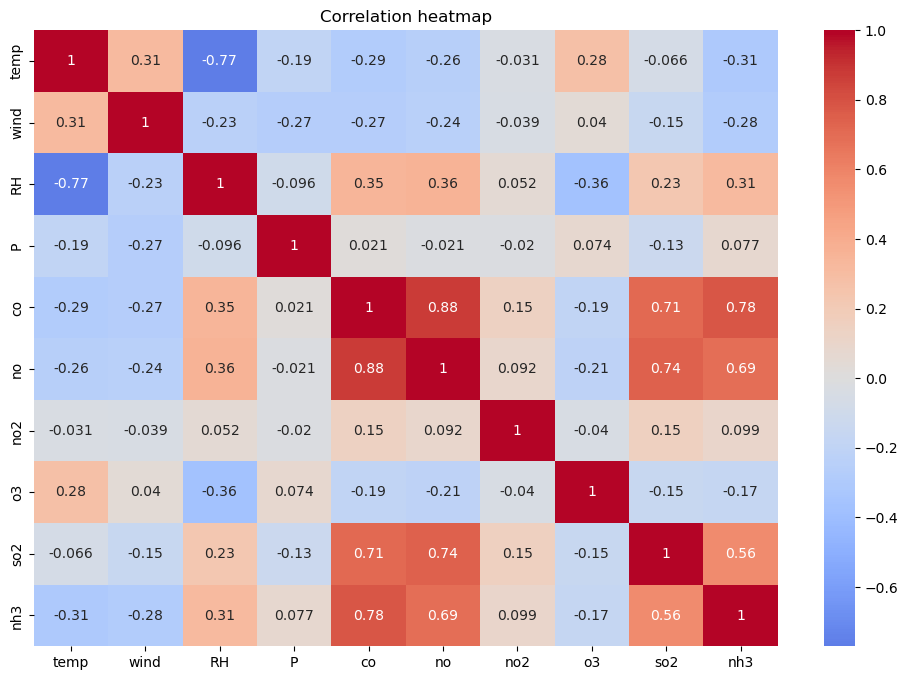

In [28]:
plt.figure(figsize=(12,8))
sns.heatmap(train[num_col].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

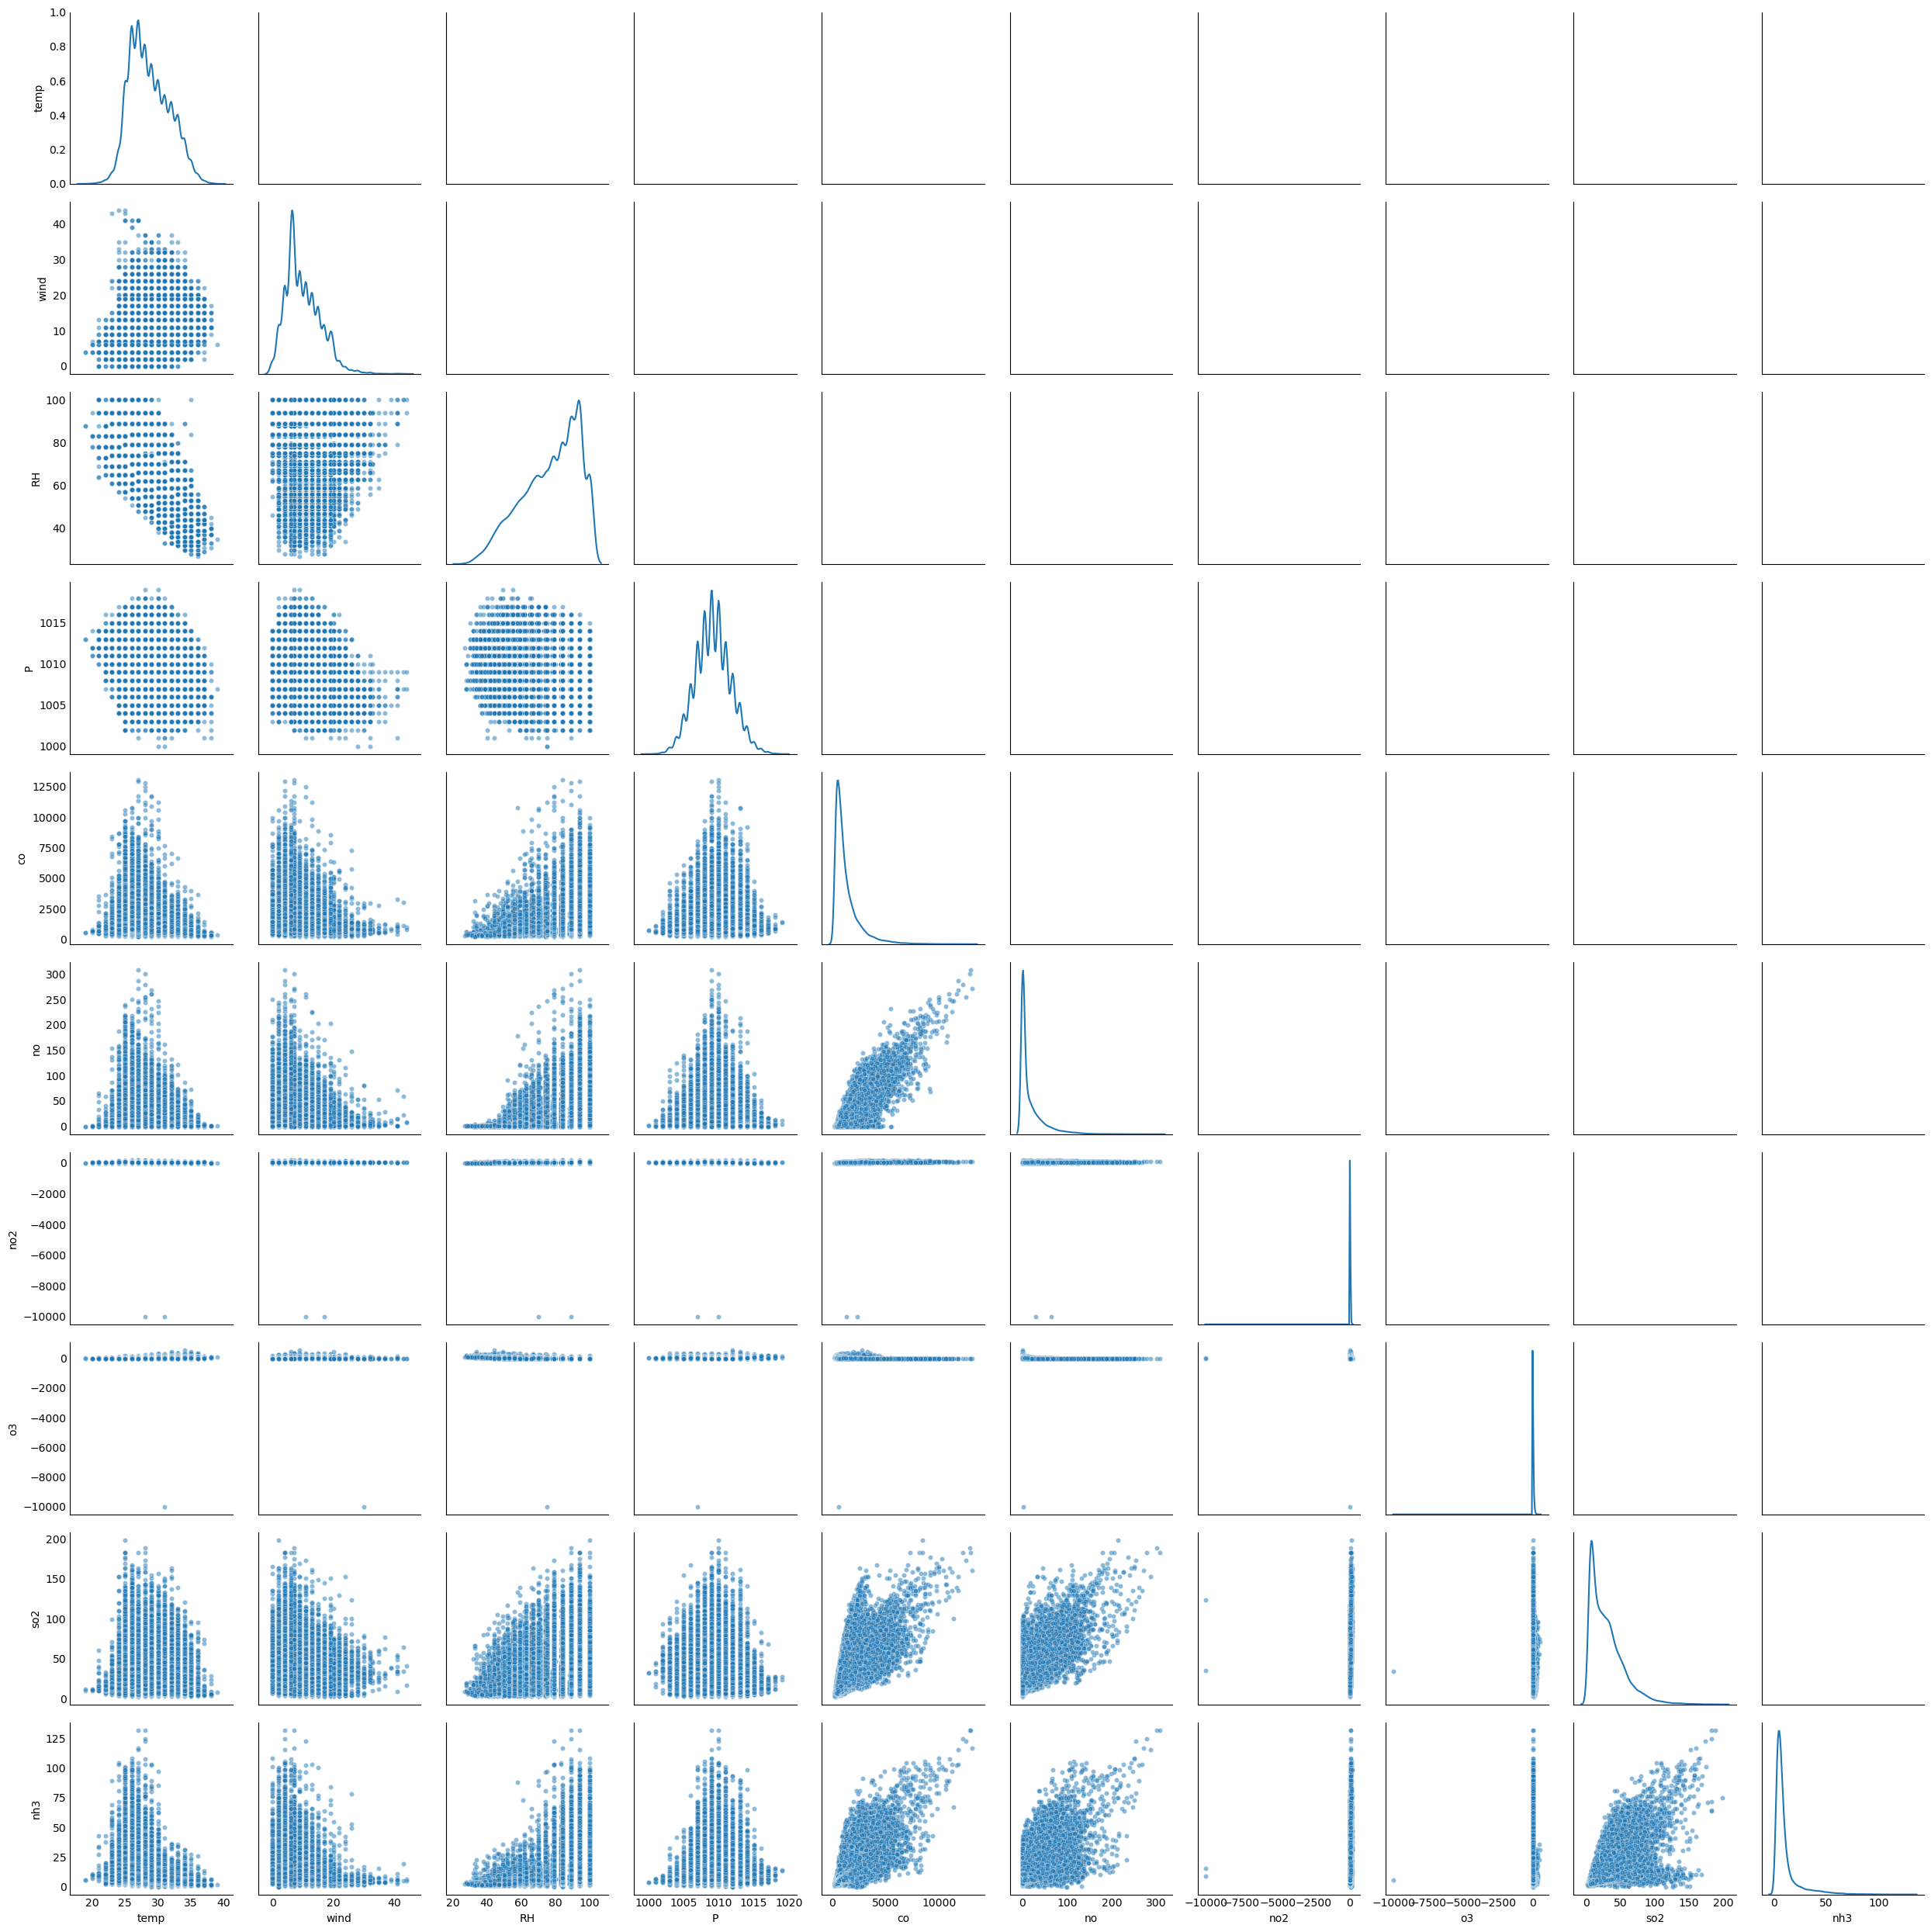

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

def scatter_lower_triangle_clean(df, num_cols):
    """
    Vẽ scatter plot nửa tam giác dưới, bỏ khung thừa.
    """
    g = sns.PairGrid(df[num_cols], diag_sharey=False)
    
    # Lower triangle scatter
    g.map_lower(sns.scatterplot, alpha=0.5, s=20)
    
    # Diagonal KDE
    g.map_diag(sns.kdeplot)
    
    # Upper triangle để trống
    g.map_upper(lambda *args, **kwargs: None)
    
    # Gỡ khung và tick labels thừa
    for ax in g.axes.flatten():
        if ax is not None:
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.tick_params(axis='both', which='both', length=0)  # ẩn ticks nhỏ
    
    plt.tight_layout()
    plt.show()

# Gọi hàm
scatter_lower_triangle_clean(train, num_col)


## 2. Univariate time series visualization

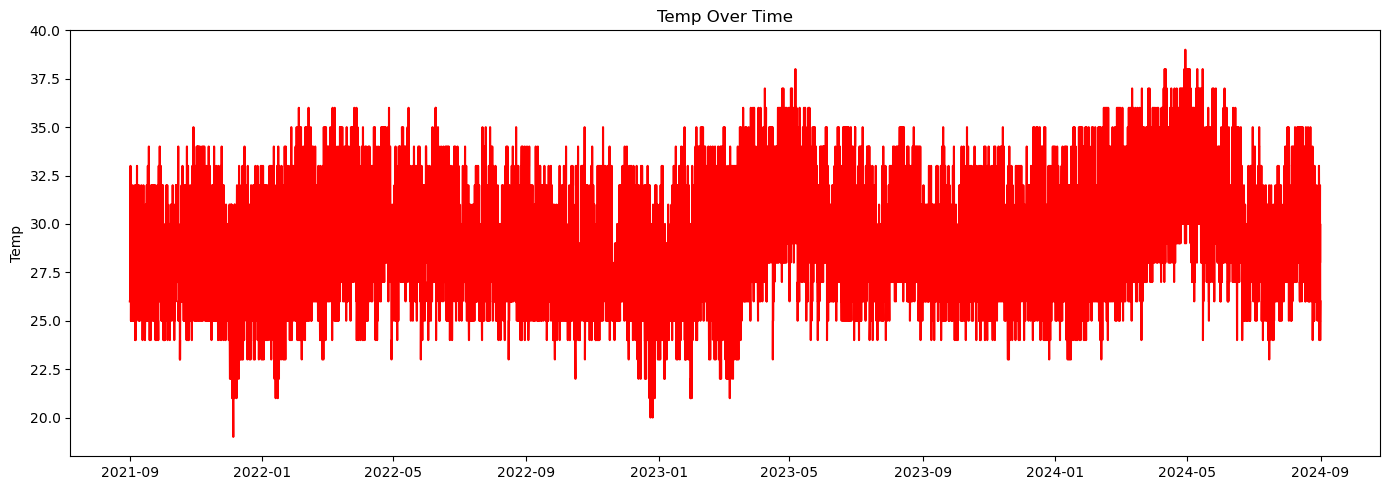

In [30]:
var = "temp"  # biến muốn vẽ

df_plot = train.copy()
df_plot["time"] = pd.to_datetime(df_plot["time"])
plt.figure(figsize=(14,5))
sns.lineplot(data=df_plot, x="time", y=var, color="red")
plt.title(f"{var.capitalize()} Over Time")
plt.xlabel("")
plt.ylabel(var.capitalize())
plt.tight_layout()
plt.show()

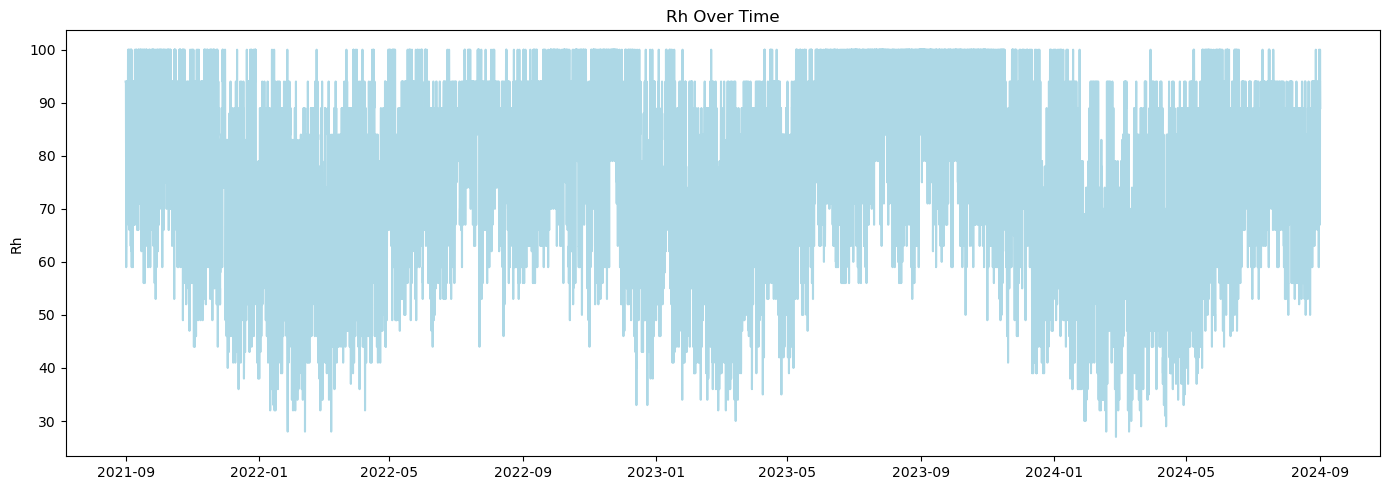

In [31]:
var = "RH"  # biến muốn vẽ

df_plot = train.copy()
df_plot["time"] = pd.to_datetime(df_plot["time"])

plt.figure(figsize=(14,5))
sns.lineplot(data=df_plot, x="time", y=var, color="lightblue")
plt.title(f"{var.capitalize()} Over Time")
plt.xlabel("")
plt.ylabel(var.capitalize())
plt.tight_layout()
plt.show()

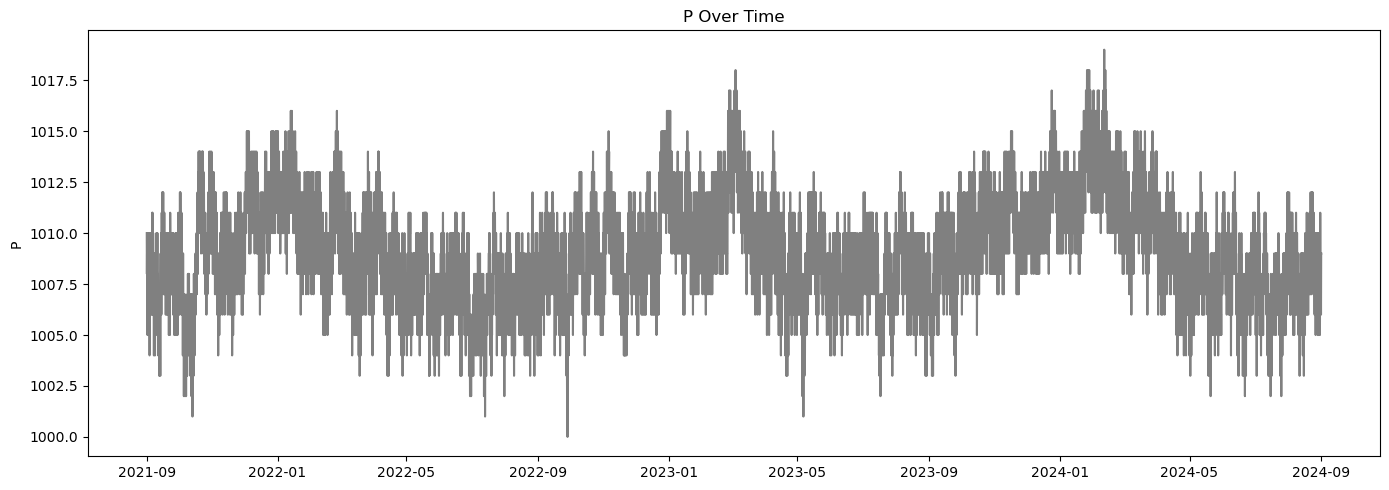

In [32]:
var = "P"  # biến muốn vẽ

df_plot = train.copy()
df_plot["time"] = pd.to_datetime(df_plot["time"])

plt.figure(figsize=(14,5))
sns.lineplot(data=df_plot, x="time", y=var, color="gray")
plt.title(f"{var.capitalize()} Over Time")
plt.xlabel("")
plt.ylabel(var.capitalize())
plt.tight_layout()
plt.show()

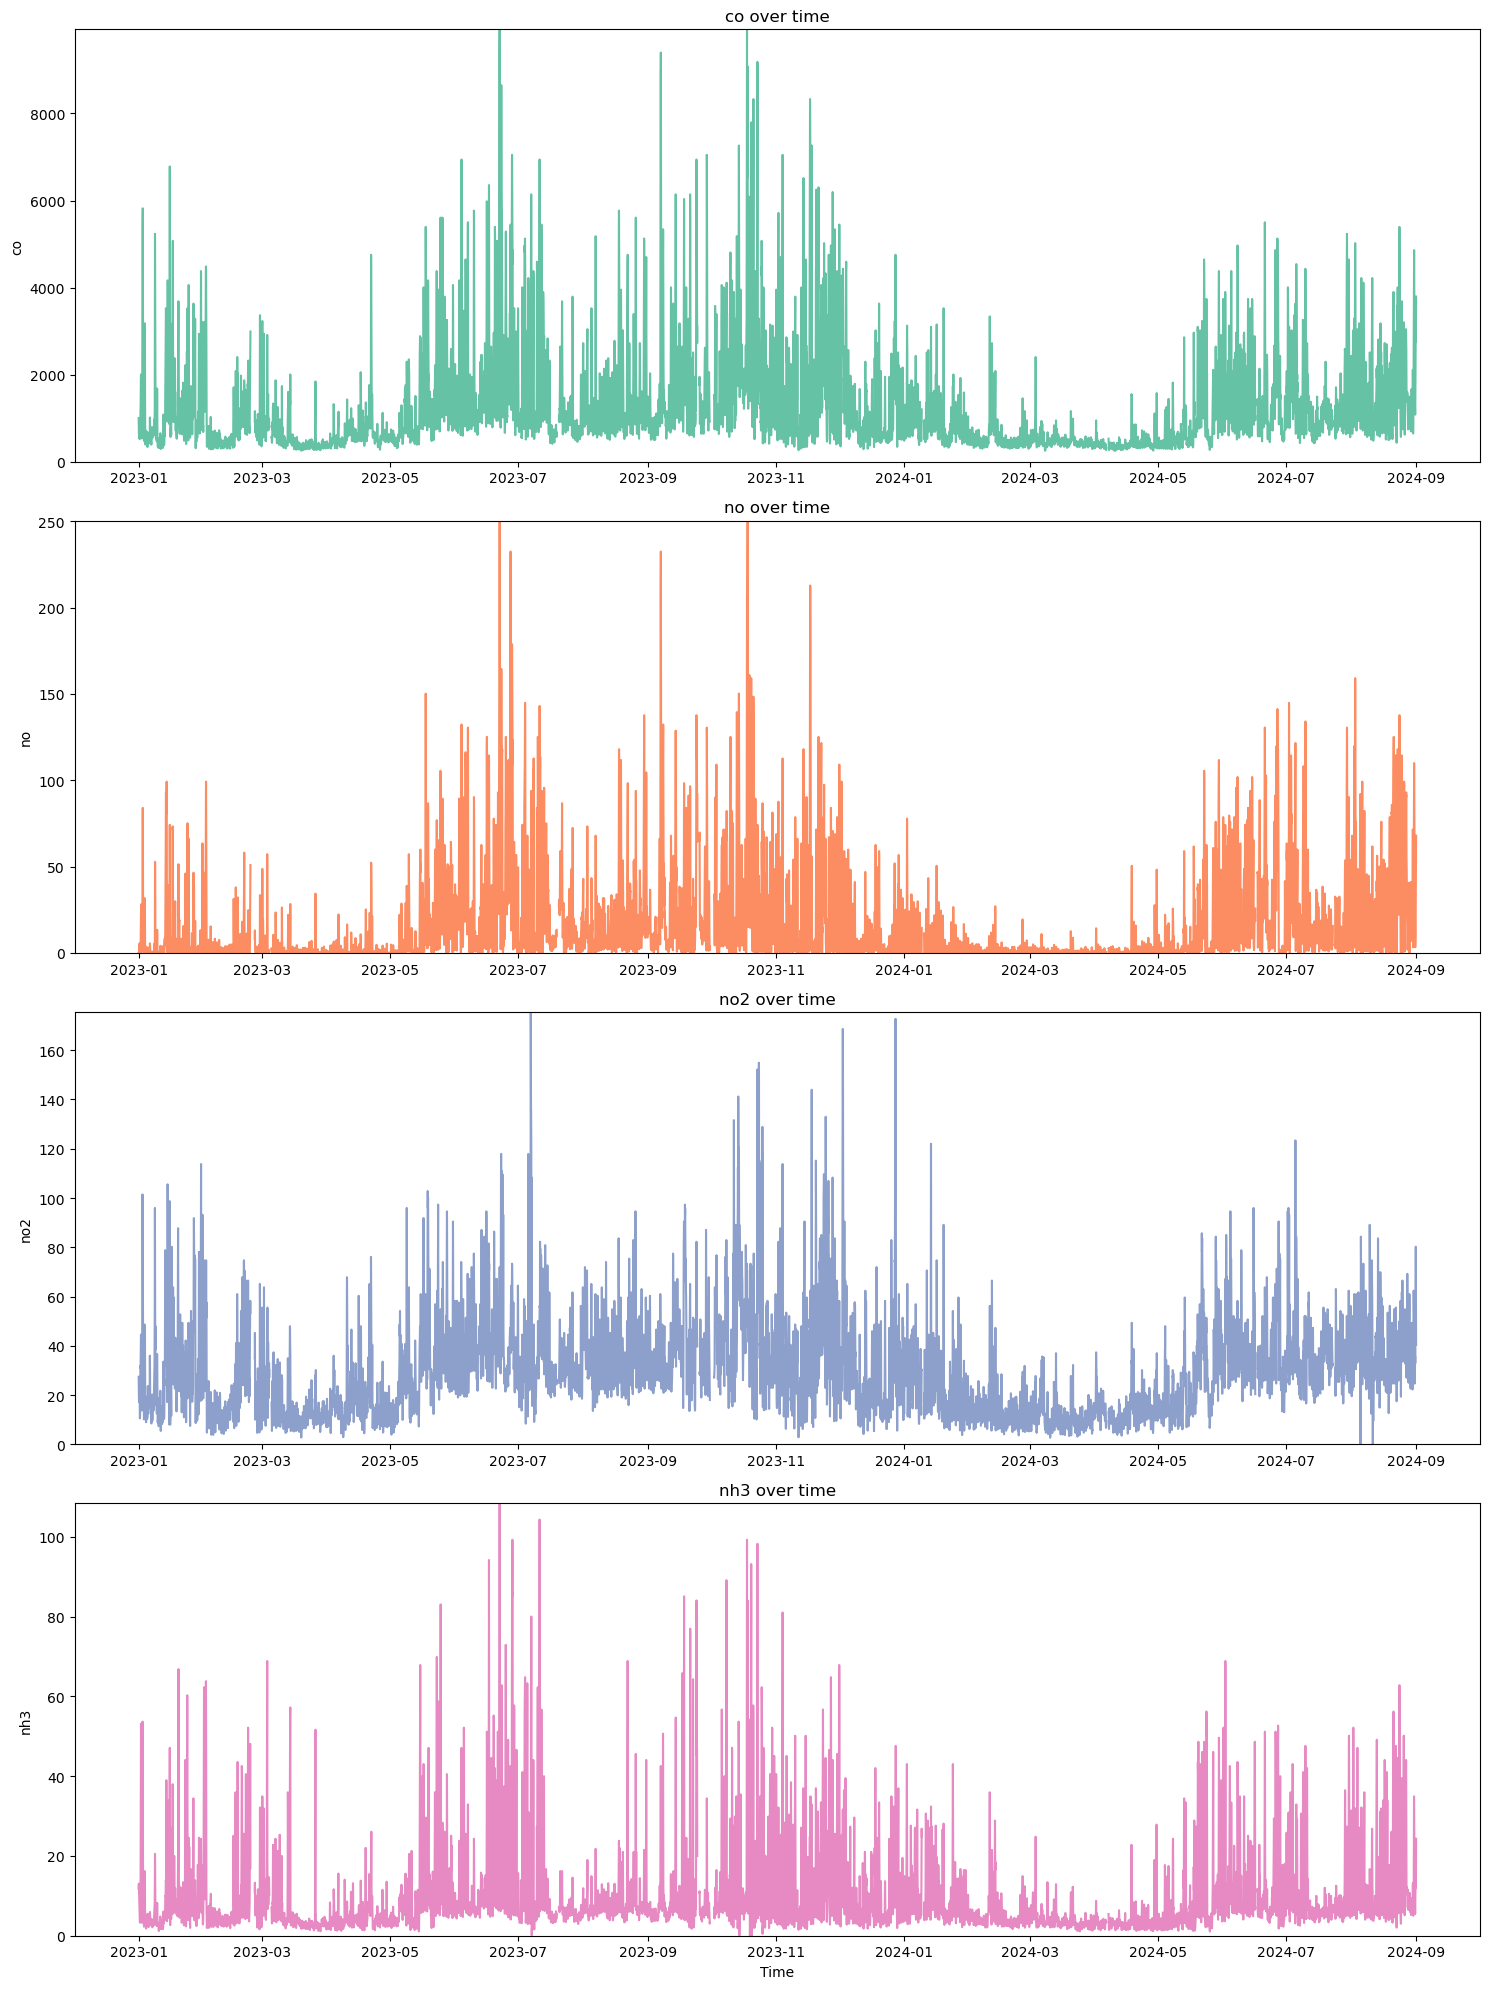

In [33]:
def plot_AQI_subplot(df, cols, start="2024-03-01", end="2025-03-19"):
    df = df.copy()
    
    # Chuyển time sang datetime nếu chưa phải
    if not pd.api.types.is_datetime64_any_dtype(df["time"]):
        df["time"] = pd.to_datetime(df["time"], errors="coerce")
    
    # Lọc theo thời gian
    if start:
        df = df[df["time"] >= pd.to_datetime(start)]
    if end:
        df = df[df["time"] <= pd.to_datetime(end)]
        
    n = len(cols)
    fig, axes = plt.subplots(n, 1, figsize=(15, 5*n))
    colors = sns.color_palette("Set2", n_colors=n)
    if n == 1:
        axes = [axes]

    for i, col in enumerate(cols):
        axes[i].plot(df["time"], df[col], label=col, color=colors[i])
        axes[i].set_title(f"{col} over time")
        axes[i].set_ylim(0, df[col].max())
        axes[i].set_ylabel(col)
    
    axes[-1].set_xlabel("Time")
    plt.tight_layout()
    plt.show()

# Gọi hàm
plot_AQI_subplot(
    train,
    cols=["co", "no", "no2", "nh3"],
    start="2023-01-01",
    end="2025-12-31"
)

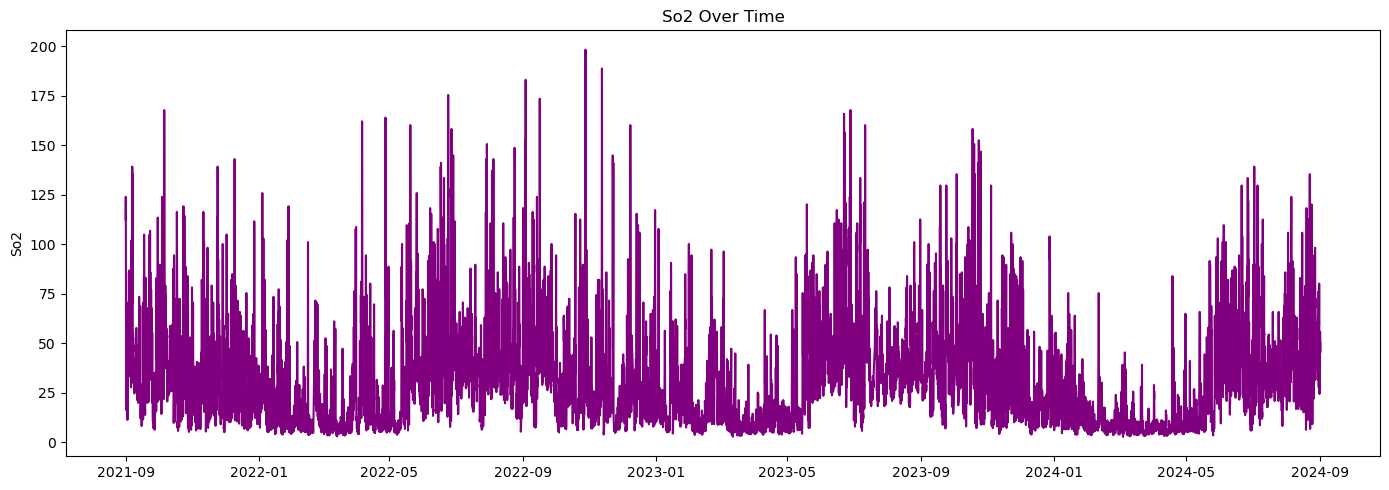

In [34]:
var = "so2"  # biến muốn vẽ

df_plot = train.copy()
df_plot["time"] = pd.to_datetime(df_plot["time"])

plt.figure(figsize=(14,5))
sns.lineplot(data=df_plot, x="time", y=var, color="purple")
plt.title(f"{var.capitalize()} Over Time")
plt.xlabel("")
plt.ylabel(var.capitalize())
plt.tight_layout()
plt.show()

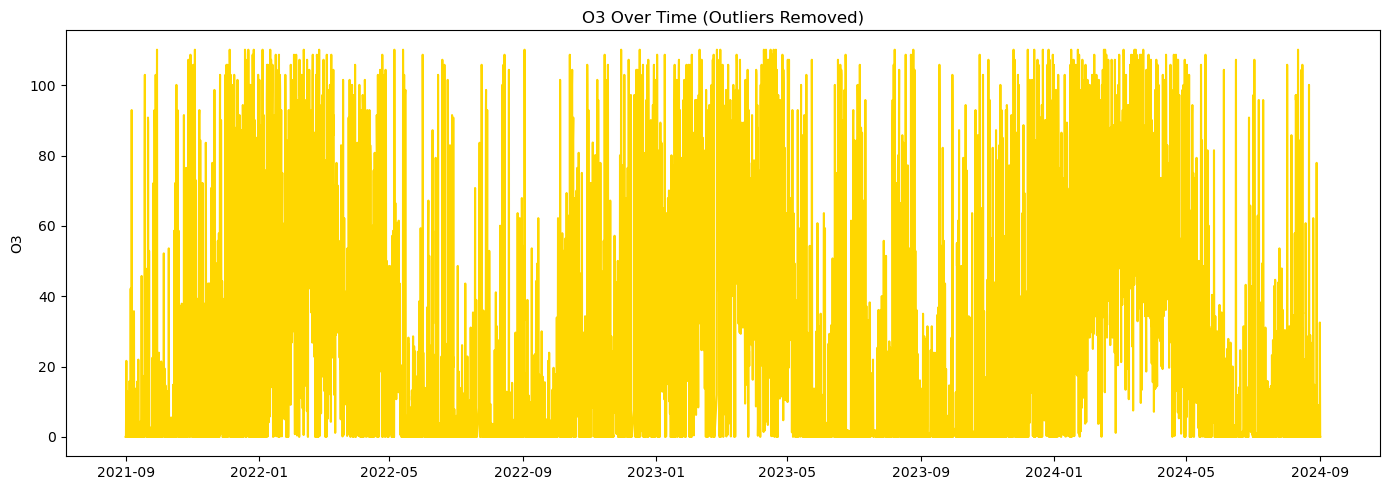

In [35]:
var = "o3"  # biến muốn vẽ

df_plot = train.copy()
df_plot["time"] = pd.to_datetime(df_plot["time"])

# Loại outlier bằng IQR
Q1 = df_plot[var].quantile(0.25)
Q3 = df_plot[var].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outlier = df_plot[(df_plot[var] >= lower) & (df_plot[var] <= upper)]

# Vẽ lineplot
plt.figure(figsize=(14,5))
sns.lineplot(data=df_no_outlier, x="time", y=var, color="gold")
plt.title(f"{var.capitalize()} Over Time (Outliers Removed)")
plt.xlabel("")
plt.ylabel(var.capitalize())
plt.tight_layout()
plt.show()


Ta thể thấy được ngoại trừ SO2, O3 thì các biến ô nhiễm khác đều có xu hướng giống nhau (ở đây NO2 đã được bỏ qua các mẫu ngoại lai):  

- Tất cả đều thấp vào giai đoạn tháng `3-5`, tăng dột biến vào tháng `6` và giữ ở mức cao trong các tháng tiếp theo, đạt đỉnh tại giai đoạn tháng `10-2`. Điều này có thể lý giải được là theo chu kỳ hoạt động của người Việt, giai đoạn tháng 3-5 là sau tết, nhu cầu di chuyển giảm bớt, người dân tập trung đi học, đi làm và chuẩn bị cho các kỳ thi quan trọng dẫn đến ô nhiễm thấp. Vào các tháng hè đặc biệt là tháng 6 và 8, nhu cầu giải trí nghỉ dưỡng tăng mạnh do học sinh được nghỉ hè nên các chỉ số ô nhiễm cũng tăng đột biến lên. Vào các tháng cuối và đầu năm mới nhu cầu di chuyển tăng trở lại để đẩy mạnh việc hoàn tất các công việc vào cuối năm và sắm sửa đồ đạc, vui chơi giải trí trong kì nghỉ Tết.
- `SO2`: thấp vào thangs 3-5, tăng vào các tháng tiếp theo với biên độ giao động mạnh. SO2 còn chịu ảnh hưởng nhiều từ quá trình đốt nhiên liệu công nghiệp, kèm với độ ẩm không khí cao vào các tháng mùa mưa dẫn đến SO2 tích tụ trong không khí nhiều hơn.
- `O3`: nồng độ Ozone thấp vào giai đoạn tháng 3-9, cao lên vào tháng 10-2 và đạt đỉnh tại tháng 1-2. Mùa khô ở Nam Bộ có nắng mạnh, ít mưa rửa sạch không khí nên tăng phản ứng quang hóa dẫn đến tăng O3. Ngược lại vào giai đoạn mùa mưa và đối lưu mùa hè nhiều mây, ít ánh sáng mặt trời, giảm quang hóa nên nồng độ O3 cũng thấp.

## 3. daily pattern plot

In [36]:
def plot_daily_pattern(data, var, start_date, days=3, step=1):
    """
    Vẽ sự thay đổi của biến var trong 24h cho các ngày cách nhau step ngày.
    
    data: DataFrame có cột 'time' và var
    var: tên biến muốn vẽ
    start_date: ngày bắt đầu, dạng 'YYYY-MM-DD'
    days: số ngày muốn vẽ (sau khi tính step)
    step: số ngày cách nhau giữa các ngày được vẽ
    """
    # copy data
    df = data.copy()
    
    # ensure time is datetime
    df['time'] = pd.to_datetime(df['time'], errors='coerce')
    
    # tạo cột 'date' và 'hour'
    df['date'] = df['time'].dt.date
    df['hour'] = df['time'].dt.hour
    
    # tạo danh sách các ngày muốn vẽ
    start_date_dt = pd.to_datetime(start_date).date()
    dates_to_plot = [start_date_dt + pd.Timedelta(days=i*step) for i in range(days)]
    
    # lọc dữ liệu
    df_plot = df[df['date'].isin(dates_to_plot)]
    
    if df_plot.empty:
        print("No data in this date range.")
        return
    
    # vẽ
    plt.figure(figsize=(14,6))
    sns.lineplot(data=df_plot, x='hour', y=var, hue='date', marker='o')
    plt.title(f'{var} pattern per hour for {days} days starting {start_date} every {step} day(s)')
    plt.xlabel('Hour of Day')
    plt.ylabel(var)
    plt.xticks(range(0,24))
    plt.legend(title='Date')
    plt.show()

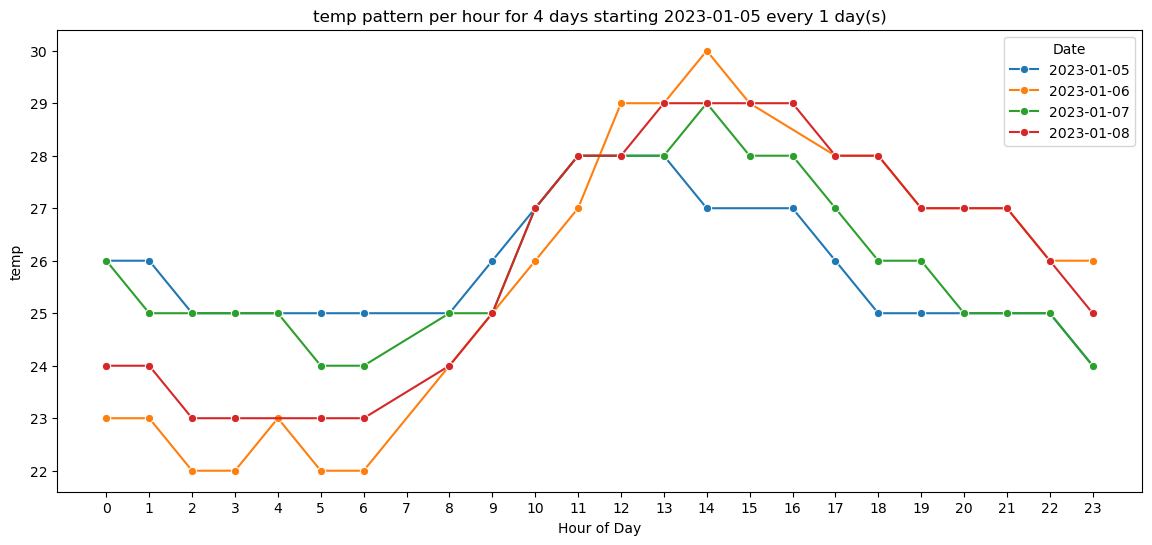

In [37]:
plot_daily_pattern(train, var='temp', start_date='2023-01-05', days=4)

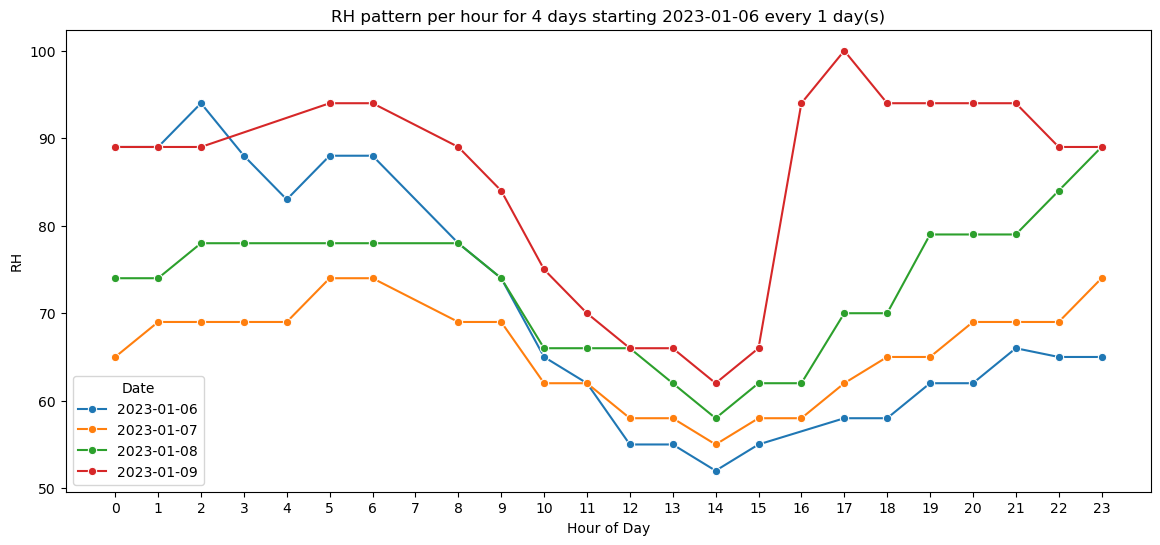

In [38]:
plot_daily_pattern(train, var='RH', start_date='2023-01-06', days=4)

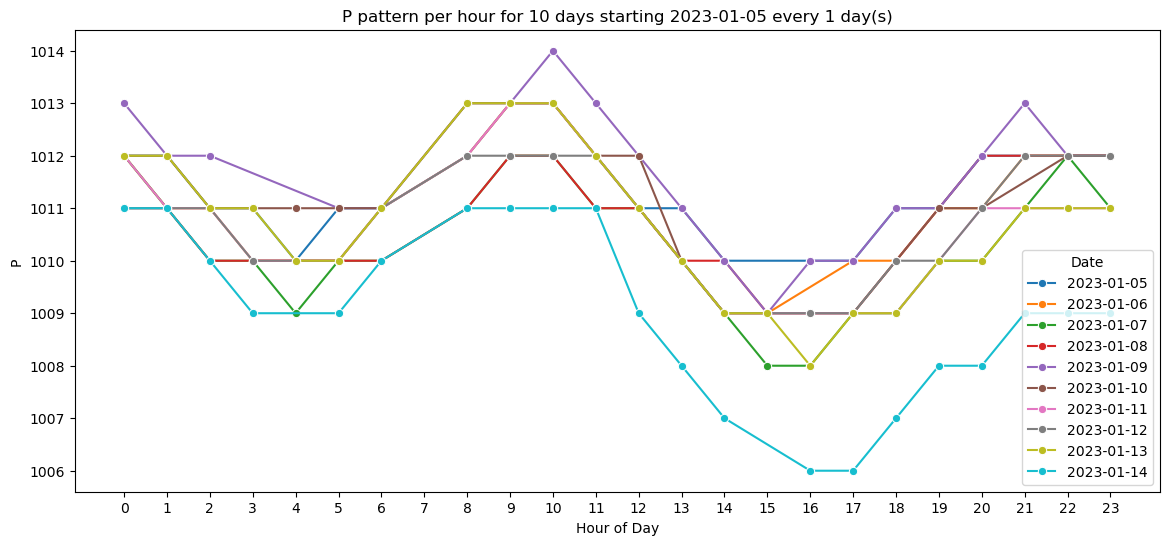

In [39]:
plot_daily_pattern(train, var='P', start_date='2023-01-05', days=10)

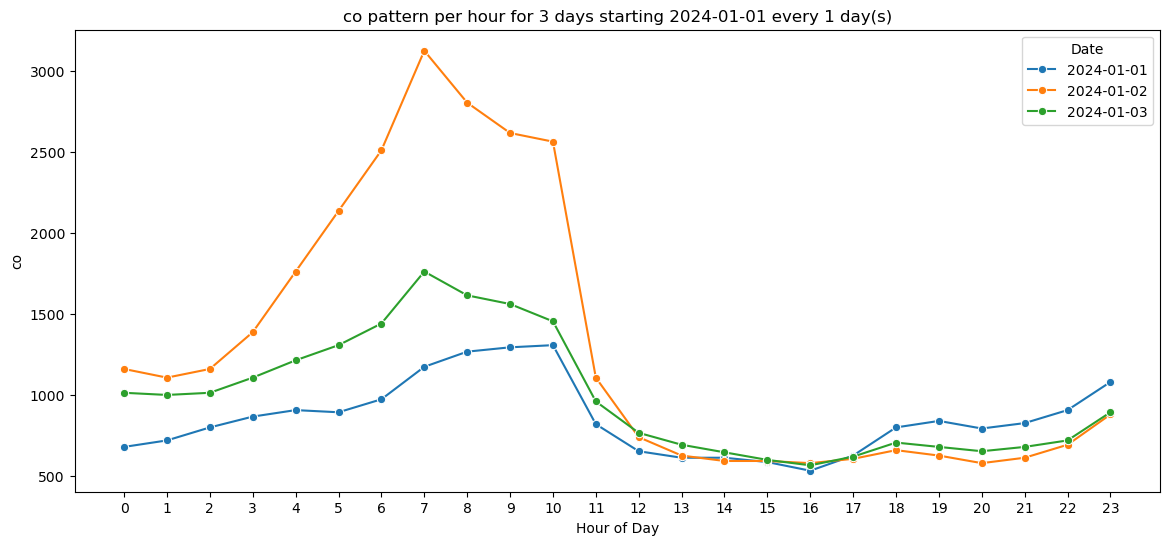

In [40]:
plot_daily_pattern(train, var='co', start_date='2024-01-01', days=3)

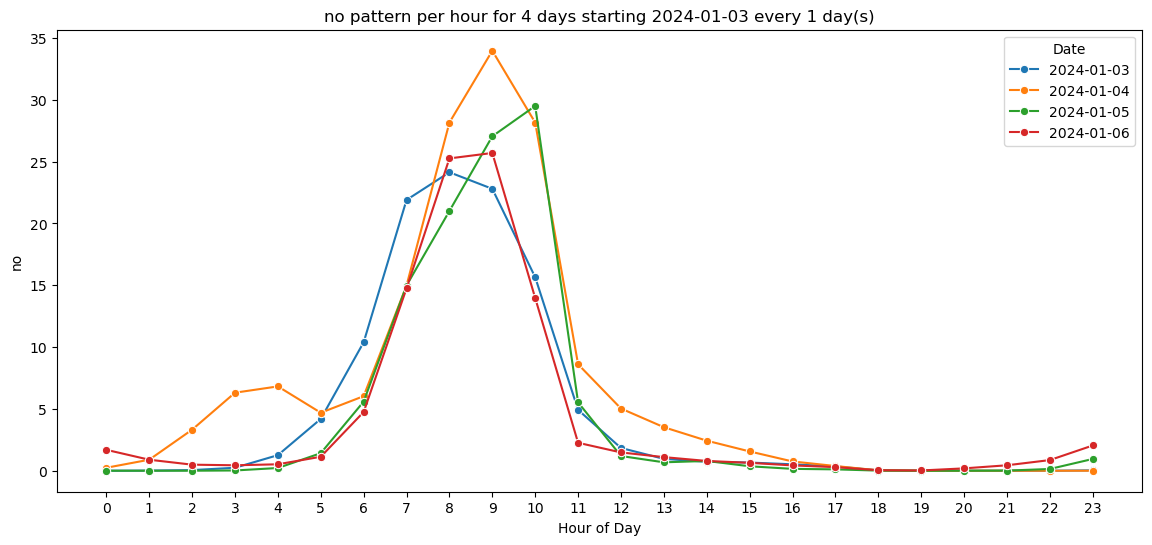

In [41]:
plot_daily_pattern(train, var='no', start_date='2024-01-03', days=4)

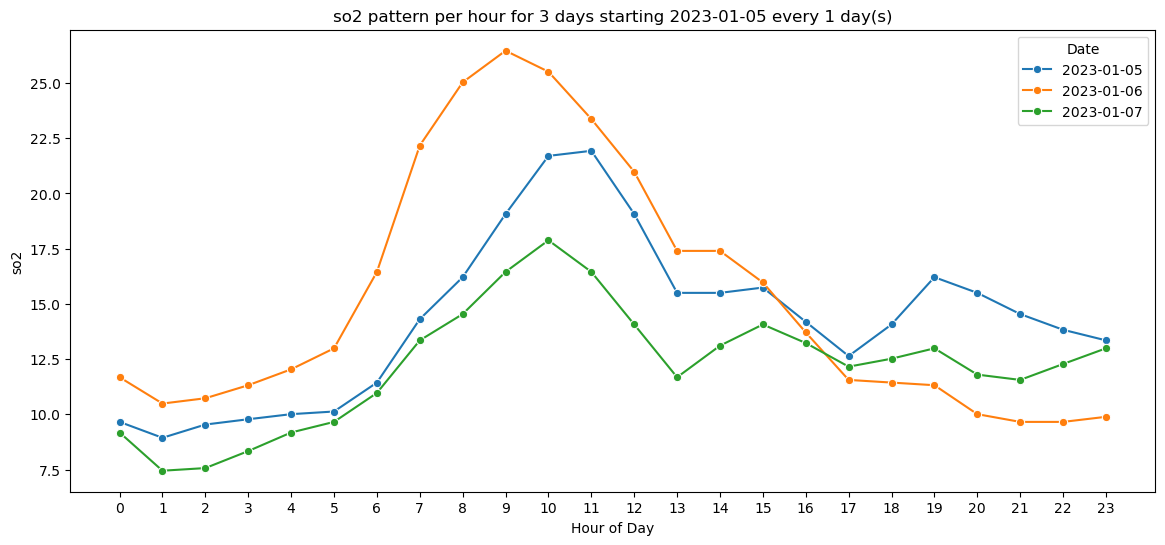

In [42]:
plot_daily_pattern(train, var='so2', start_date='2023-01-05', days=3)

Ta có thể thấy các yếu tố thời tiết và các chất đều tuân theo pattern theo ngày rất rõ ràng.

## 4. Weather

C:\Users\Admin\AppData\Local\Temp\ipykernel_25364\420066809.py:20: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


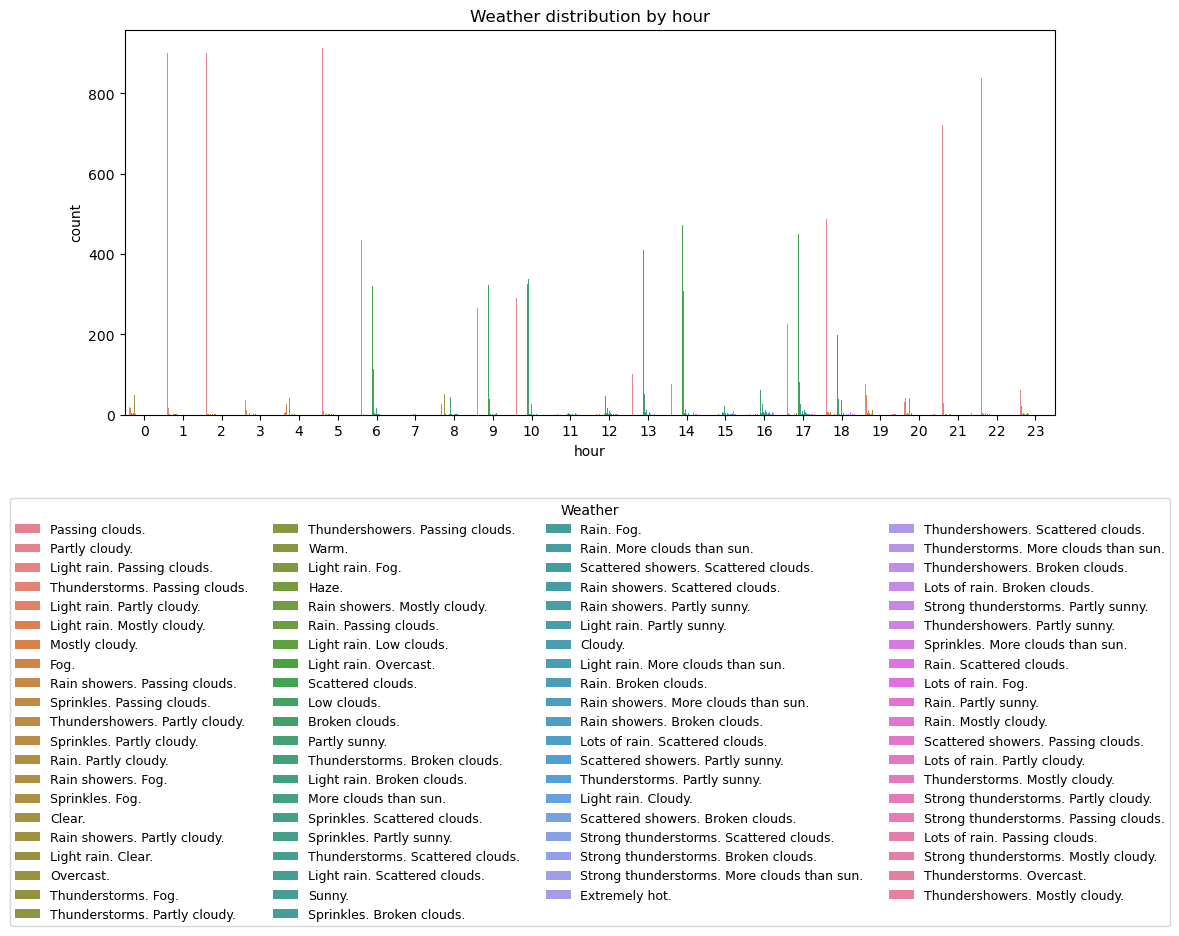

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

df = train.copy()  # copy DataFrame để giữ nguyên train
df['time'] = pd.to_datetime(df['time'])
df['hour'] = df['time'].dt.hour

plt.figure(figsize=(12,5))
ax = sns.countplot(x='hour', hue='weather', data=df)

plt.title("Weather distribution by hour")

# 📌 Đưa legend xuống dưới, chia thành nhiều cột (ncol)
plt.legend(title="Weather",
           bbox_to_anchor=(0.5, -0.2),   # căn giữa dưới biểu đồ
           loc='upper center',
           ncol=4,                       # số cột (có thể chỉnh)
           fontsize=9)

plt.tight_layout()
plt.show()

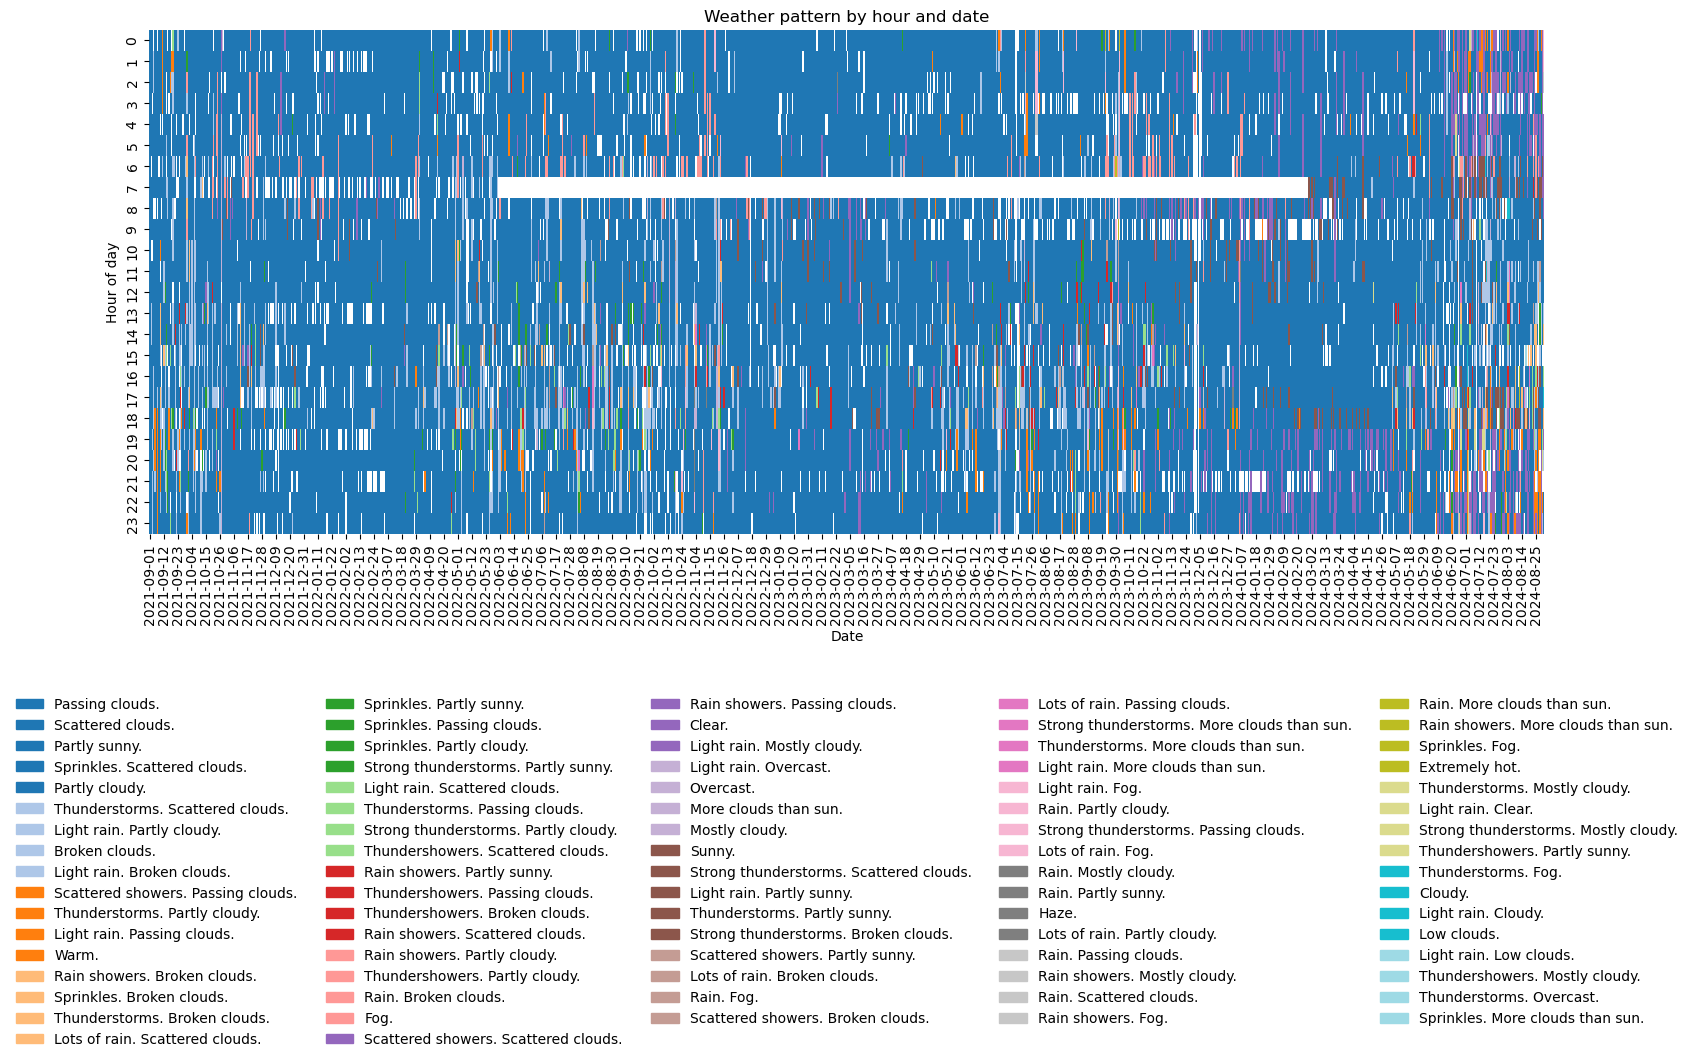

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import pandas as pd

# copy DataFrame và convert time
df = train.copy()
df["time"] = pd.to_datetime(df["time"])

# tạo cột ngày và giờ
df['date'] = df['time'].dt.date
df['hour'] = df['time'].dt.hour

# map weather sang số
weather_map = {w: i for i, w in enumerate(df['weather'].dropna().unique())}
df['weather_code'] = df['weather'].map(weather_map)

# pivot table: hàng = giờ, cột = ngày, giá trị = weather code
pivot = df.pivot_table(index='hour', columns='date', values='weather_code', aggfunc='first')

# vẽ heatmap
plt.figure(figsize=(18,8))
sns.heatmap(pivot, cmap="tab20", cbar=False)
plt.title("Weather pattern by hour and date")
plt.xlabel("Date")
plt.ylabel("Hour of day")

# tạo legend riêng
patches = [mpatches.Patch(color=plt.cm.tab20(i / len(weather_map)), label=weather)
           for weather, i in weather_map.items()]

plt.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, -0.3),
           ncol=5, frameon=False)

plt.subplots_adjust(bottom=0.25)  # tạo khoảng trống cho legend
plt.show()

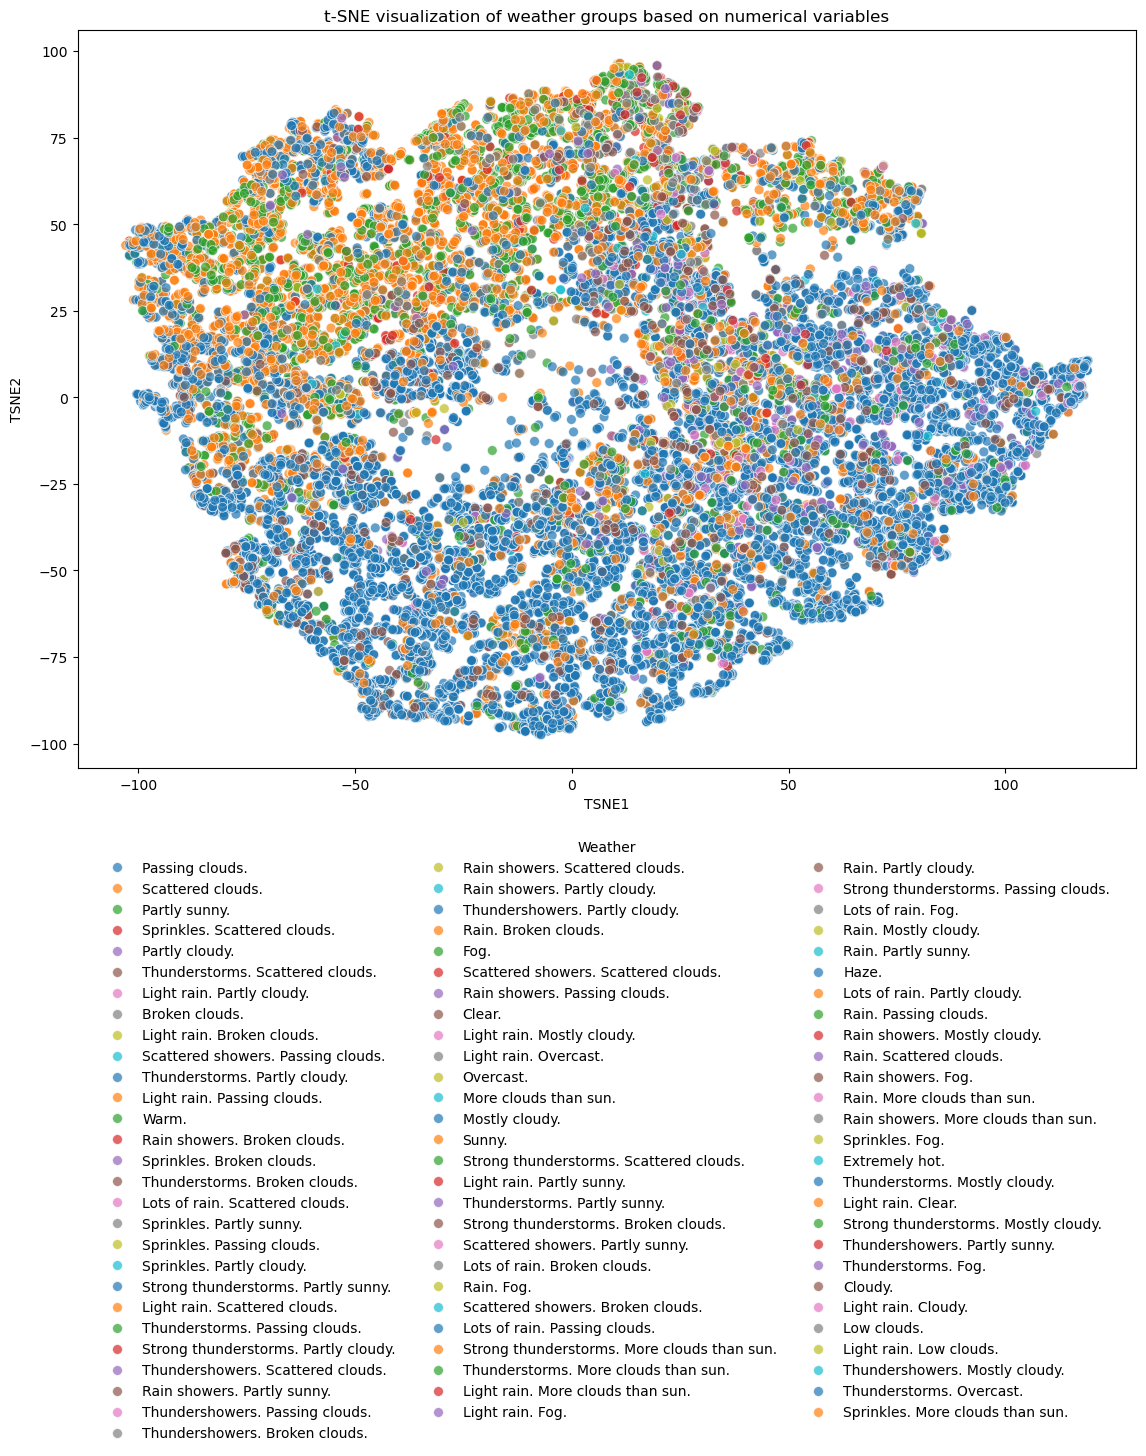

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# copy data
df = train.copy()
df["time"] = pd.to_datetime(df["time"])

# Chuẩn hóa dữ liệu và điền NaN
X = df[num_col].fillna(df[num_col].mean())
X_scaled = StandardScaler().fit_transform(X)

# t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(X_scaled)

# DataFrame t-SNE
df_tsne = pd.DataFrame(X_embedded, columns=['TSNE1', 'TSNE2'])
df_tsne['weather'] = df['weather'].values

# Vẽ scatter plot
plt.figure(figsize=(12,15))
sns.scatterplot(data=df_tsne, x='TSNE1', y='TSNE2', hue='weather', palette='tab10', s=50, alpha=0.7)
plt.title("t-SNE visualization of weather groups based on numerical variables")

# Legend xuống dưới, chia nhiều dòng
plt.legend(title='Weather', bbox_to_anchor=(0.5, -0.08), loc='upper center', ncol=3, frameon=False)

plt.tight_layout()
plt.show()

Nhận xét:
- Có thể quan sát rằng, đối với mỗi giờ trong ngày, luôn tồn tại một loại thời tiết chiếm ưu thế.
- Các giờ gần nhau thường có điều kiện thời tiết tương tự
- Khi thực hiện phân cụm, các nhóm thời tiết không được tách biệt rõ ràng